In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../data/raw/Quality of Service 5G.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Timestamp            400 non-null    object
 1   User_ID              400 non-null    object
 2   Application_Type     400 non-null    object
 3   Signal_Strength      400 non-null    object
 4   Latency              400 non-null    object
 5   Required_Bandwidth   400 non-null    object
 6   Allocated_Bandwidth  400 non-null    object
 7   Resource_Allocation  400 non-null    object
dtypes: object(8)
memory usage: 25.1+ KB


,Timestamp,User_ID,Application_Type,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
0,9/3/2023 10:00,User_1,Video_Call,-75 dBm,30 ms,10 Mbps,15 Mbps,70%
1,9/3/2023 10:00,User_2,Voice_Call,-80 dBm,20 ms,100 Kbps,120 Kbps,80%
2,9/3/2023 10:00,User_3,Streaming,-85 dBm,40 ms,5 Mbps,6 Mbps,75%
3,9/3/2023 10:00,User_4,Emergency_Service,-70 dBm,10 ms,1 Mbps,1.5 Mbps,90%
4,9/3/2023 10:00,User_5,Online_Gaming,-78 dBm,25 ms,2 Mbps,3 Mbps,85%


In [2]:
ground_truth = df['Application_Type']
ground_truth.to_csv('../data/processed/ground_truth_labels.csv', index=False)

features_raw = df.drop(columns=['User_ID', 'Timestamp', 'Application_Type'])
features_raw.head()

,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
0,-75 dBm,30 ms,10 Mbps,15 Mbps,70%
1,-80 dBm,20 ms,100 Kbps,120 Kbps,80%
2,-85 dBm,40 ms,5 Mbps,6 Mbps,75%
3,-70 dBm,10 ms,1 Mbps,1.5 Mbps,90%
4,-78 dBm,25 ms,2 Mbps,3 Mbps,85%


In [3]:
def parse_bandwidth(val):
    val = str(val).strip()
    if 'Mbps' in val:
        return float(val.replace('Mbps', '').strip())
    elif 'Kbps' in val:
        return float(val.replace('Kbps', '').strip()) / 1000.0
    return float(val)

def parse_signal(val):
    return float(str(val).replace('dBm', '').strip())

def parse_latency(val):
    return float(str(val).replace('ms', '').strip())

def parse_resource(val):
    return float(str(val).replace('%', '').strip())

In [4]:
df_clean = pd.DataFrame()
df_clean['Signal_Strength'] = features_raw['Signal_Strength'].apply(parse_signal)
df_clean['Latency'] = features_raw['Latency'].apply(parse_latency)
df_clean['Required_Bandwidth'] = features_raw['Required_Bandwidth'].apply(parse_bandwidth)
df_clean['Allocated_Bandwidth'] = features_raw['Allocated_Bandwidth'].apply(parse_bandwidth)
df_clean['Resource_Allocation'] = features_raw['Resource_Allocation'].apply(parse_resource)

df_clean.describe()

,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
count,400.000000,400.000000,400.000000,400.000000,400.000000
mean,-80.495000,33.825000,3.135512,3.502380,74.712500
std,20.701119,21.122139,3.984097,4.460801,8.982291
min,-123.000000,0.000000,0.000000,0.000000,50.000000
25%,-98.000000,21.750000,0.417500,0.417500,70.000000
50%,-83.000000,31.000000,1.200000,1.350000,70.000000
75%,-64.000000,45.000000,4.100000,4.425000,80.000000
max,-40.000000,110.000000,14.500000,15.800000,90.000000


                     Signal_Strength   Latency  Required_Bandwidth  \
Signal_Strength             1.000000 -0.392676            0.461366   
Latency                    -0.392676  1.000000            0.002935   
Required_Bandwidth          0.461366  0.002935            1.000000   
Allocated_Bandwidth         0.447047  0.003295            0.998181   
Resource_Allocation         0.303580 -0.137848            0.072394   

                     Allocated_Bandwidth  Resource_Allocation  
Signal_Strength                 0.447047             0.303580  
Latency                         0.003295            -0.137848  
Required_Bandwidth              0.998181             0.072394  
Allocated_Bandwidth             1.000000             0.076741  
Resource_Allocation             0.076741             1.000000  


<Figure size 800x700 with 0 Axes>

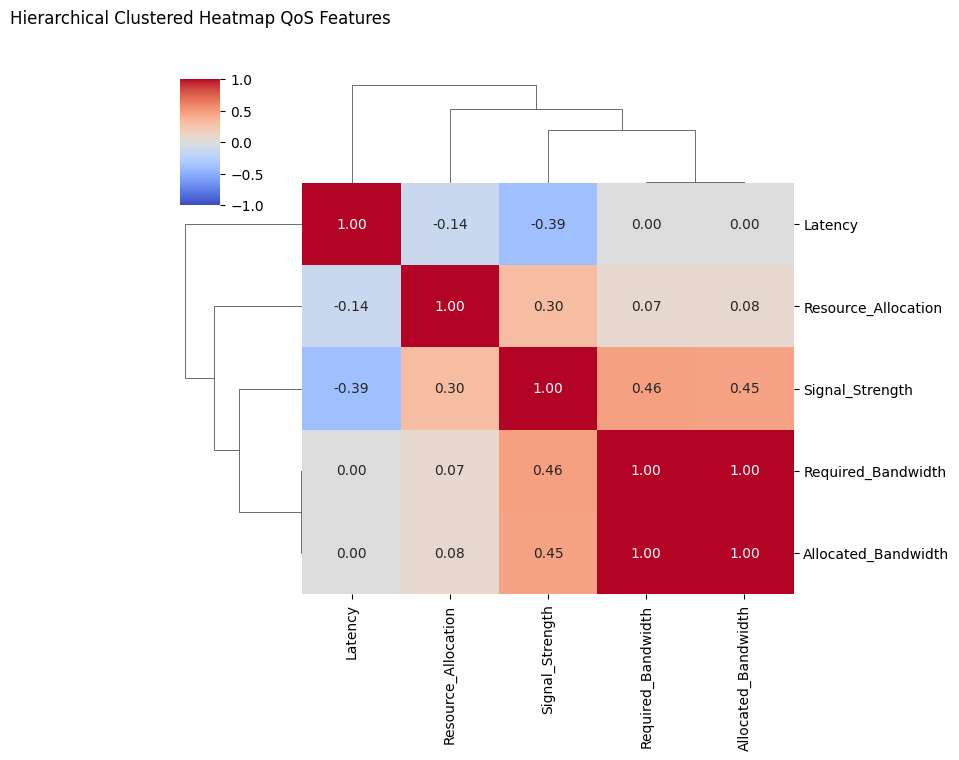

In [6]:
corr_matrix = df_clean.corr()
print(corr_matrix)

plt.figure(figsize=(8, 7))
clustermap = sns.clustermap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    figsize=(8, 7)
)
plt.title("Hierarchical Clustered Heatmap QoS Features", pad=40)
plt.savefig('../outputs/figures/01_clustered_heatmap.png', bbox_inches='tight', dpi=300)
plt.show()

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

scaled_df = pd.DataFrame(X_scaled, columns=df_clean.columns)

print("Scaled Means:")
print(np.round(scaled_df.mean(), 4))

print("\nScaled Standard Deviations:")
print(np.round(scaled_df.std(), 4))

scaled_df.to_csv('../data/processed/data_scaled.csv', index=False)

Scaled Means:
Signal_Strength        0.0
Latency               -0.0
Required_Bandwidth     0.0
Allocated_Bandwidth   -0.0
Resource_Allocation   -0.0
dtype: float64

Scaled Standard Deviations:
Signal_Strength        1.0013
Latency                1.0013
Required_Bandwidth     1.0013
Allocated_Bandwidth    1.0013
Resource_Allocation    1.0013
dtype: float64
